In [1]:
from pathlib import Path
import numpy as np
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent

train = pd.read_parquet(ROOT / "data" / "processed" / "train.parquet")
print(train.shape)
print("default rate:", round(train["TARGET"].mean() * 100, 2), "%")


(215257, 108)
default rate: 8.07 %


In [2]:
df = train[["EXT_SOURCE_3", "TARGET"]].copy()
df["bin"] = pd.qcut(df["EXT_SOURCE_3"], q=5)            # 5 equal-sized bins
df["bin"] = df["bin"].cat.add_categories("Missing").fillna("Missing")

t = df.groupby("bin", observed=True)["TARGET"].agg(n="count", bad="sum")
t["good"] = t["n"] - t["bad"]
t["default_rate"] = t["bad"] / t["n"]

t["pct_good"] = t["good"] / t["good"].sum()   # share of ALL goods in this bin
t["pct_bad"]  = t["bad"]  / t["bad"].sum()    # share of ALL bads in this bin
t["woe"] = np.log(t["pct_good"] / t["pct_bad"])
t["iv"]  = (t["pct_good"] - t["pct_bad"]) * t["woe"]

print("IV =", round(t["iv"].sum(), 3))
t.round(3)


IV = 0.315


,n,bad,good,default_rate,pct_good,pct_bad,woe,iv
bin,,,,,,,,
"(-0.000473, 0.331]",34808,5728,29080,0.165,0.147,0.330,-0.808,0.148
"(0.331, 0.476]",34499,3041,31458,0.088,0.159,0.175,-0.096,0.002
"(0.476, 0.59]",34364,1947,32417,0.057,0.164,0.112,0.380,0.020
"(0.59, 0.694]",35331,1600,33731,0.045,0.170,0.092,0.616,0.048
"(0.694, 0.896]",33710,1126,32584,0.033,0.165,0.065,0.933,0.093
Missing,42545,3935,38610,0.092,0.195,0.226,-0.149,0.005


In [3]:
from optbinning import OptimalBinning

optb = OptimalBinning(name="EXT_SOURCE_3", dtype="numerical",
                      monotonic_trend="auto_asc_desc")
optb.fit(train["EXT_SOURCE_3"].values, train["TARGET"].values)

bt = optb.binning_table.build()
print("IV =", round(bt.loc["Totals", "IV"], 3))
bt


(CVXPY) Nov 10 07:13:14 AM: Encountered unexpected exception importing solver HIGHS:
ImportError('/home/fiza/Credit_Risk/.venv/lib/python3.12/site-packages/highspy/_core.cpython-312-x86_64-linux-gnu.so: undefined symbol: _ZN5Highs13releaseMemoryEv')


IV = 0.34


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 0.18)",10843,0.050372,8443,2400,0.221341,-1.174644,1.121155e-01,1.326051e-02
1,"[0.18, 0.32)",20780,0.096536,17784,2996,0.144177,-0.651492,5.377362e-02,6.605295e-03
2,"[0.32, 0.41)",21237,0.098659,19183,2054,0.096718,-0.198278,4.215316e-03,5.260530e-04
3,"[0.41, 0.47)",16008,0.074367,14713,1295,0.080897,-0.002293,3.912263e-07,4.890328e-08
4,"[0.47, 0.53)",14612,0.067882,13713,899,0.061525,0.292303,5.134167e-03,6.394959e-04
5,"[0.53, 0.57)",12576,0.058423,11848,728,0.057888,0.3571,6.420734e-03,7.983544e-04
6,"[0.57, 0.63)",22277,0.103490,21192,1085,0.048705,0.53953,2.409346e-02,2.975678e-03
7,"[0.63, 0.67)",11817,0.054897,11306,511,0.043243,0.664206,1.841773e-02,2.260809e-03
8,"[0.67, 0.70)",11348,0.052718,10898,450,0.039655,0.754574,2.201656e-02,2.688583e-03
9,"[0.70, 0.76)",16336,0.075891,15769,567,0.034709,0.892929,4.202156e-02,5.084864e-03


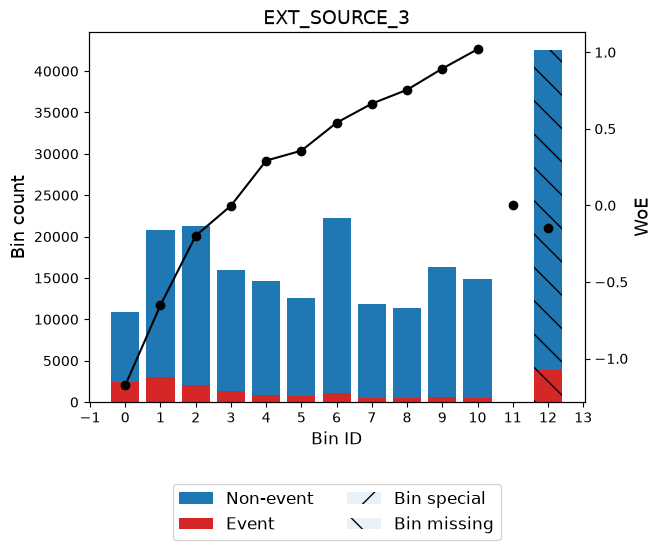

In [4]:
optb.binning_table.plot(metric="woe")
